<a href="https://colab.research.google.com/github/Meysha3106/PengolahanCitraDigital_Meysha_TI24H/blob/main/Tugas_Praktek_PCD_6_Meysha_20240040220.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


1.a Translasi Citra

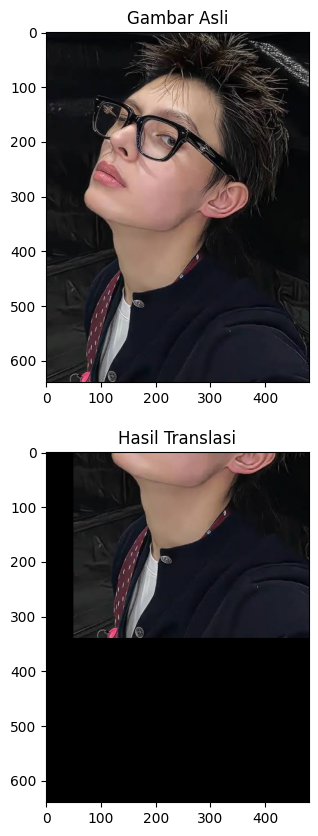

In [11]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def Translasi(image, shiftX, shiftY):
    # Geser piksel secara melingkar
    imgTranslasi = np.roll(image, shift=shiftY, axis=0) # Geser vertikal
    imgTranslasi = np.roll(imgTranslasi, shift=shiftX, axis=1) # Geser horizontal

    # Mengisi bagian yang kosong/terpotong dengan warna hitam (0)
    if shiftY > 0:
        imgTranslasi[:shiftY, :] = 0  # Bagian atas jika geser ke bawah
    elif shiftY < 0:
        imgTranslasi[shiftY:, :] = 0  # Bagian bawah jika geser ke atas

    if shiftX > 0:
        imgTranslasi[:, :shiftX] = 0  # Bagian kiri jika geser ke kanan
    elif shiftX < 0:
        imgTranslasi[:, shiftX:] = 0  # Bagian kanan jika geser ke kiri

    return imgTranslasi

# 1. Baca gambar (sesuaikan 'tiger.jpg' dengan nama/path file gambar kamu)
image = img.imread("/content/drive/MyDrive/mey/james gue.jpg")

# 2. Panggil fungsi Translasi (geser kanan 50 piksel, geser atas 300 piksel)
imgResult = Translasi(image, shiftX=50, shiftY=-300)

# 3. Tampilkan hasil perbandingan gambar asli dan hasil translasi
plt.figure(figsize=(10, 10))

plt.subplot(2, 1, 1)
plt.title("Gambar Asli")
plt.imshow(image)

plt.subplot(2, 1, 2)
plt.title("Hasil Translasi")
plt.imshow(imgResult)

plt.show()

1.b Mirroring

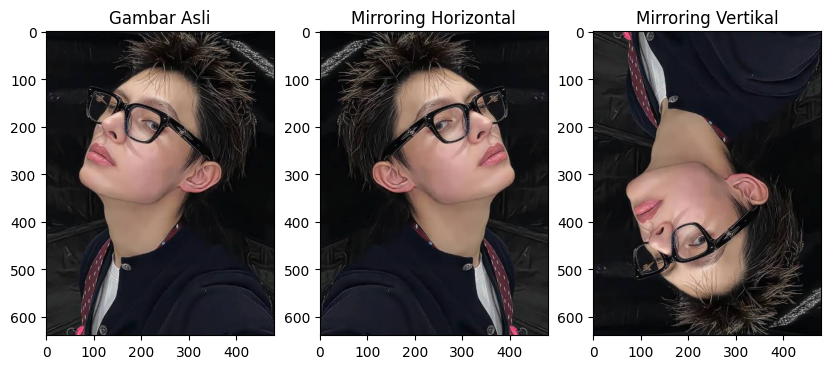

In [13]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt

# 1. Baca gambar (sesuaikan path/lokasi file gambar kamu)
path = '/content/drive/MyDrive/mey/james gue.jpg'
image = img.imread(path)

# 2. Ambil dimensi gambar (tinggi dan lebar)
height, width = image.shape[:2]

# 3. Siapkan matriks kosong untuk menampung hasil mirroring
horizontal = np.zeros_like(image)
vertical = np.zeros_like(image)

# 4. Mirroring Horizontal (membalik kolom dari kanan ke kiri)
for y in range(height):
    for x in range(width):
        horizontal[y, x] = image[y, width - 1 - x]

# 5. Mirroring Vertikal (membalik baris dari bawah ke atas)
for y in range(height):
    for x in range(width):
        vertical[y, x] = image[height - 1 - y, x]

# 6. Tampilkan hasil perbandingan
plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.title("Gambar Asli")
plt.imshow(image)

plt.subplot(1, 3, 2)
plt.title("Mirroring Horizontal")
plt.imshow(horizontal)

plt.subplot(1, 3, 3)
plt.title("Mirroring Vertikal")
plt.imshow(vertical)

plt.show()

1.c Rotasi

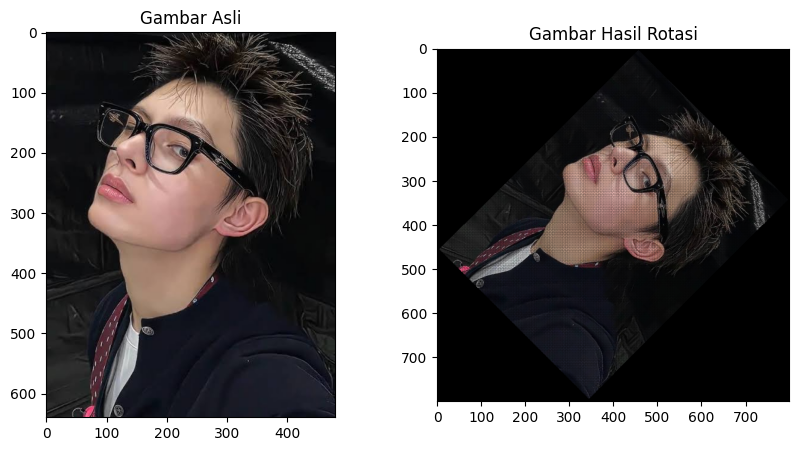

In [14]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def rotateImage(image, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    # Deteksi jumlah channel secara dinamis (RGB=3, RGBA=4, atau Grayscale=1)
    channels = image.shape[2] if len(image.shape) > 2 else 1

    max_dim = int(np.sqrt(height**2 + width**2))

    if channels > 1:
        outputImage = np.zeros((max_dim, max_dim, channels), dtype=image.dtype)
    else:
        outputImage = np.zeros((max_dim, max_dim), dtype=image.dtype)

    centerY, centerX = max_dim // 2, max_dim // 2

    for y in range(-height // 2, height // 2):
        for x in range(-width // 2, width // 2):
            newX = int(cos_deg * x - sin_deg * y) + centerX
            newY = int(sin_deg * x + cos_deg * y) + centerY

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = image[y + height // 2, x + width // 2]

    return outputImage

# 1. Baca gambar (sesuaikan path/lokasi file gambar kamu)
image = img.imread('/content/drive/MyDrive/mey/james gue.jpg')

# 2. Putar gambar sejauh 45 derajat
rotated_image = rotateImage(image, 45)

# 3. Tampilkan hasil perbandingan
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Gambar Asli")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Gambar Hasil Rotasi")
plt.imshow(rotated_image)

plt.show()

1.d Zooming

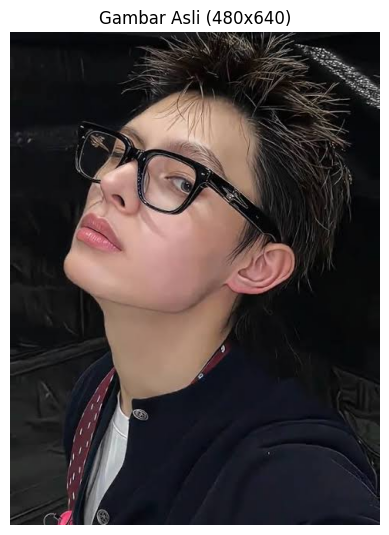

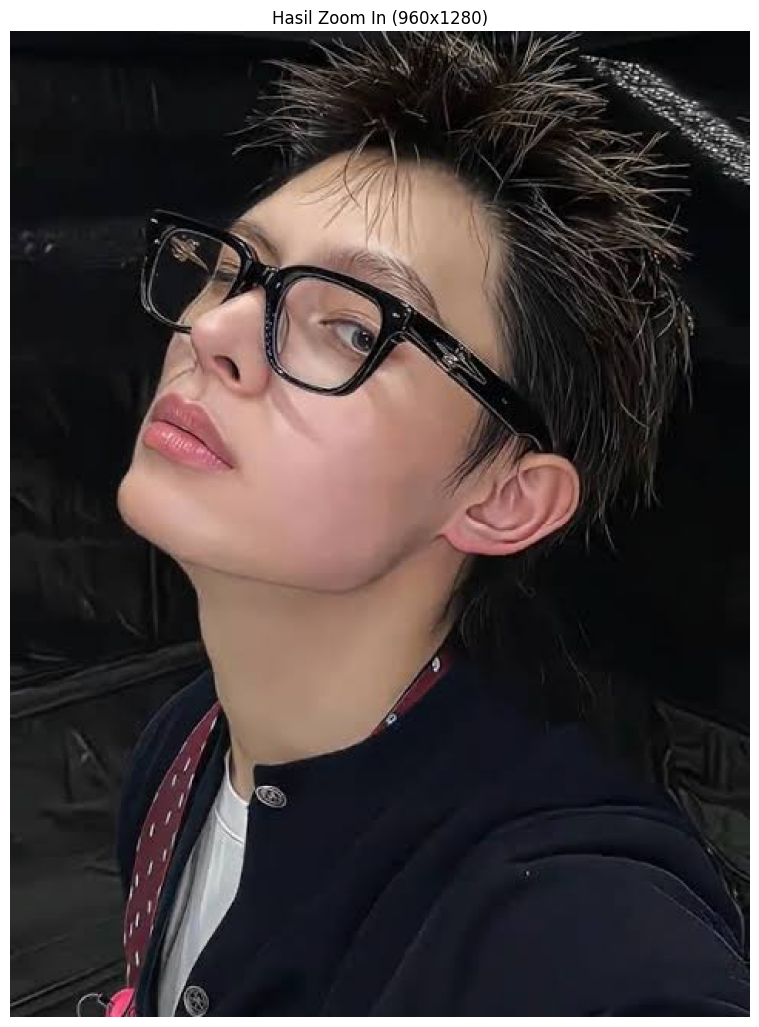

In [15]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt

def zoomPlus(image, factor):
    height, width = image.shape[:2]
    new_height = int(height * factor)
    new_width = int(width * factor)

    channels = image.shape[2] if len(image.shape) > 2 else 1

    if channels > 1:
        imgZoom = np.zeros((new_height, new_width, channels), dtype=image.dtype)
    else:
        imgZoom = np.zeros((new_height, new_width), dtype=image.dtype)

    for y in range(new_height):
        for x in range(new_width):
            ori_y = int(y / factor)
            ori_x = int(x / factor)

            ori_y = min(ori_y, height - 1)
            ori_x = min(ori_x, width - 1)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom

# 1. Baca gambar asli
image = img.imread('/content/drive/MyDrive/mey/james gue.jpg')
skala = 2.0

# 2. Panggil fungsi zoomPlus
imgZoom = zoomPlus(image, skala)

# Simpan hasil perbesaran ke file baru
img.imwrite("/content/drive/MyDrive/mey/james gue.jpg", imgZoom)

# 3. Tampilkan hasil perbandingan dalam 2 figure terpisah (Proporsional sesuai piksel)
h1, w1 = image.shape[:2]
h2, w2 = imgZoom.shape[:2]

# Gambar Asli
plt.figure(figsize=(w1/100, h1/100))
plt.title(f"Gambar Asli ({w1}x{h1})")
plt.imshow(image)
plt.axis('off')
plt.show()

# Hasil Zoom In (Tampilan akan 2x lebih besar di layar)
plt.figure(figsize=(w2/100, h2/100))
plt.title(f"Hasil Zoom In ({w2}x{h2})")
plt.imshow(imgZoom)
plt.axis('off')
plt.show()

**2.a Mirroring Vertikal dan Horizontal Secara Bersamaan**

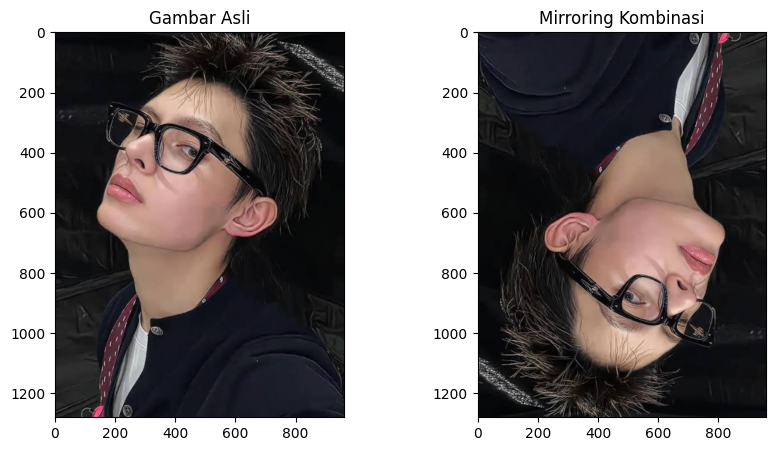

In [16]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt

image = img.imread('/content/drive/MyDrive/mey/james gue.jpg')
height, width = image.shape[:2]

combined = np.zeros_like(image)

# Membalik posisi x dan y secara bersamaan
for y in range(height):
    for x in range(width):
        combined[y, x] = image[height - 1 - y, width - 1 - x]

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Gambar Asli")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Mirroring Kombinasi")
plt.imshow(combined)
plt.show()

2.b Rotasi Citra dengan Pivot di Titik (0,0) Pojok Kiri Atas

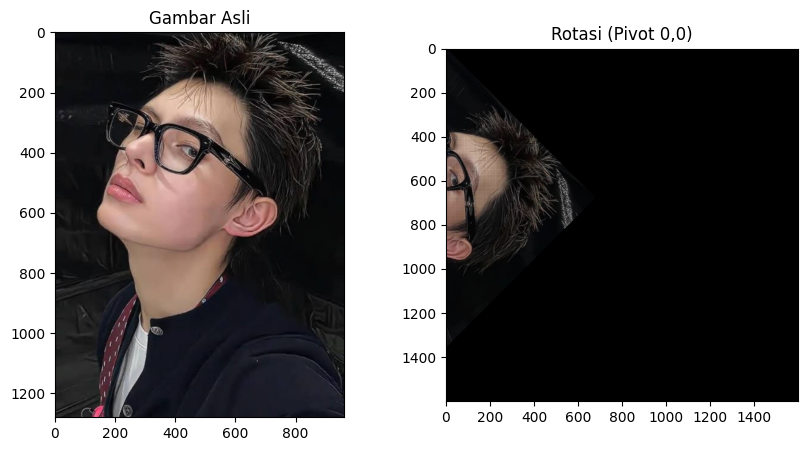

In [17]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def rotatePivotTopLeft(image, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    # Deteksi jumlah channel secara dinamis (RGB=3, RGBA=4, atau Grayscale=1)
    channels = image.shape[2] if len(image.shape) > 2 else 1

    max_dim = int(np.sqrt(height**2 + width**2))

    if channels > 1:
        outputImage = np.zeros((max_dim, max_dim, channels), dtype=image.dtype)
    else:
        outputImage = np.zeros((max_dim, max_dim), dtype=image.dtype)

    # Perhitungan tanpa pergeseran ke tengah (pivot tetap di 0,0)
    for y in range(height):
        for x in range(width):
            newX = int(cos_deg * x - sin_deg * y)
            newY = int(sin_deg * x + cos_deg * y)

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = image[y, x]

    return outputImage

image = img.imread('/content/drive/MyDrive/mey/james gue.jpg')
rotated_image = rotatePivotTopLeft(image, 45)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Gambar Asli")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Rotasi (Pivot 0,0)")
plt.imshow(rotated_image)
plt.show()

2c. Zoom Minus untuk Memperkecil Gambar

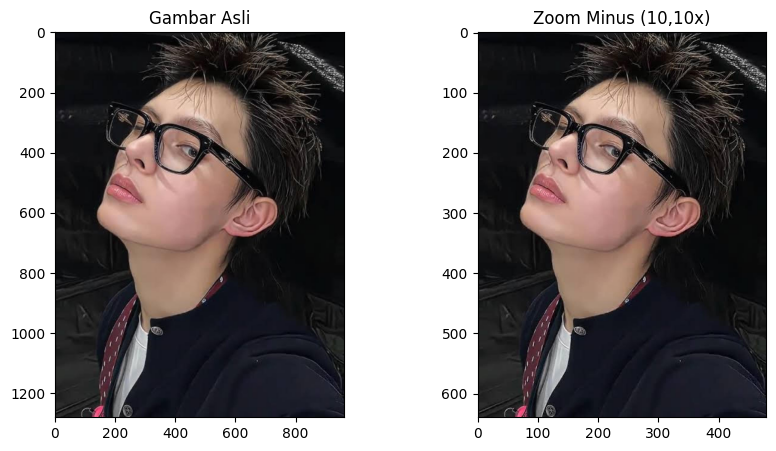

In [20]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt

def zoomMinus(image, factor):
    height, width = image.shape[:2]
    # Ukuran baru menjadi lebih kecil
    new_height = int(height * factor)
    new_width = int(width * factor)

    # Deteksi jumlah channel secara dinamis (RGB = 3, RGBA = 4, Grayscale = 1)
    channels = image.shape[2] if len(image.shape) > 2 else 1

    if channels > 1:
        imgZoom = np.zeros((new_height, new_width, channels), dtype=image.dtype)
    else:
        imgZoom = np.zeros((new_height, new_width), dtype=image.dtype)

    for y in range(new_height):
        for x in range(new_width):
            ori_y = int(y / factor)
            ori_x = int(x / factor)

            ori_y = min(ori_y, height - 1)
            ori_x = min(ori_x, width - 1)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom

image = img.imread('/content/drive/MyDrive/mey/james gue.jpg')
skala = 0.5  # Skala < 1.0 untuk memperkecil

imgZoom = zoomMinus(image, skala)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Gambar Asli")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Zoom Minus (10,10x)")
plt.imshow(imgZoom)
plt.show()